<a href="https://colab.research.google.com/github/loudamn78-gif/thakaa-flow-training/blob/main/week3/day16/day16.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## الخطوة الأولى: فهم المشكلة

**سؤال المشروع:**  
ما العوامل التي قد تكون مرتبطة بإصابة المرأة بمرض السكري؟

**المتغير المستهدف (Target):**  
العمود Outcome، حيث تمثل القيمة 1 وجود الإصابة بالسكري، وتمثل القيمة 0 عدم الإصابة.

**المستفيد من التحليل:**  
يمكن أن تستفيد عيادة السكري من نتائج التحليل للتعرف على الفئات الأكثر عرضة للإصابة بالمرض والمساعدة في الكشف المبكر.

**وصف البيانات:**  
تحتوي البيانات على معلومات لـ 768 امرأة، وتشمل عدة قياسات طبية مثل مستوى الجلوكوز، ضغط الدم، مؤشر كتلة الجسم (BMI)، العمر، وعدد مرات الحمل.

**هدفي من التحليل:**  
هدفي هو فهم البيانات واستكشافها، والتأكد من جودتها، ومعالجة أي قيم مفقودة أو غير منطقية، ثم تحديد أكثر العوامل ارتباطًا بالإصابة بالسكري وتجهيز البيانات لاستخدامها في بناء نموذج تنبؤي.

**توقعاتي:**  
أتوقع أن يكون مستوى الجلوكوز والعمر ومؤشر كتلة الجسم من أكثر العوامل ارتباطًا بالإصابة بالسكري، بسبب تأثيرها المعروف على خطر الإصابة بالمرض.

In [22]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('diabetes.csv')
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


#: أول نظرة على الداتا

In [23]:
print("الحجم:", df.shape)
df.info()

الحجم: (768, 9)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


##كودالنقص والتكرار

In [24]:
print("القيم الناقصة:")
print(df.isnull().sum())
print("\nعدد الصفوف المكررة:", df.duplicated().sum())

القيم الناقصة:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

عدد الصفوف المكررة: 0


## الاحصائيات

In [25]:
df.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


## الاصفار مهمه لسؤال التفكير

In [26]:
cols = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
print((df[cols] == 0).sum())

Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64


## ملاحظاتي من النظرة الأولية على البيانات

- تحتوي البيانات على 768 سجلًا و9 أعمدة، وجميع البيانات عبارة عن قيم رقمية.
- عند فحص القيم المفقودة لم تظهر أي قيم فارغة، لكن هذا لا يعني بالضرورة أن البيانات نظيفة بالكامل.
- لاحظت وجود قيم تساوي صفرًا في بعض المتغيرات الطبية مثل الجلوكوز وضغط الدم ومؤشر كتلة الجسم، وهي قيم غير منطقية طبيًا، لذلك من المحتمل أنها تمثل بيانات مفقودة.
- أكثر الأعمدة التي لفتت انتباهي كانت SkinThickness وInsulin، لأن عدد القيم الصفرية فيهما كبير مقارنة بباقي الأعمدة.
- لذلك أعتقد أن جزءًا من البيانات المفقودة مخزن على شكل أصفار بدلًا من قيم فارغة، ولهذا لم يظهر في الفحص الأولي.
- في الخطوات القادمة سأحوّل هذه القيم غير المنطقية إلى NaN ثم أحدد أفضل طريقة لمعالجتها قبل البدء بالتحليل وبناء النموذج.

##: EDA بالرسومات

## رسمة توزيع الtarget

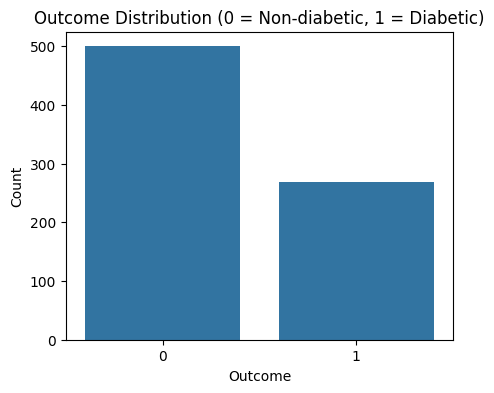

Outcome
0    500
1    268
Name: count, dtype: int64
Outcome
0    65.104167
1    34.895833
Name: proportion, dtype: float64


In [27]:
plt.figure(figsize=(5,4))
sns.countplot(x='Outcome', data=df)
plt.title('Outcome Distribution (0 = Non-diabetic, 1 = Diabetic)')
plt.xlabel('Outcome')
plt.ylabel('Count')
plt.show()
print(df['Outcome'].value_counts())
print(df['Outcome'].value_counts(normalize=True) * 100)



**الملاحظة:** من 768 امرأة، 500 غير مصابة (65.1%) و268 مصابة (34.9%). يعني الداتا مو متوازنة تمامًا، وغير المصابات تقريبًا ضعف المصابات.

##رسمة توزيع الجلوكوز حسب الاصابة

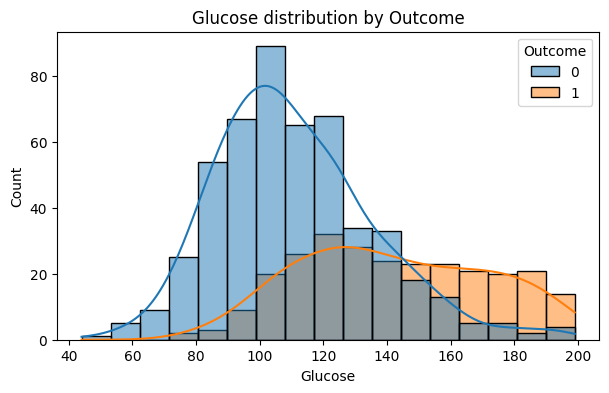

In [28]:
plt.figure(figsize=(7,4))
sns.histplot(data=df[df['Glucose'] > 0], x='Glucose', hue='Outcome', kde=True)
plt.title('Glucose distribution by Outcome')
plt.show()

**الملاحظة:** المصابات (البرتقالي) جلوكوزهن أعلى بوضوح؛ أغلب غير المصابات يتركزن حول 100، بينما المصابات يتوزعن من 120 إلى 200. وفوق 160 تقريبًا أغلب الحالات مصابات. (استبعدت الأصفار من الرسمة عشان ما تشوّه التوزيع.)

## رسمة الارتباط مع ال Target

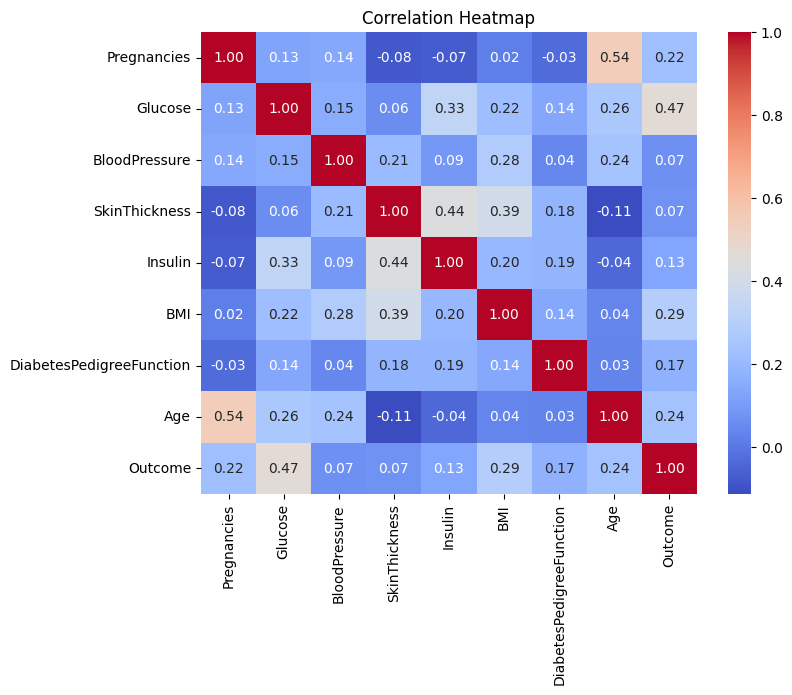

In [29]:
plt.figure(figsize=(8,6))
sns.heatmap(df.corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()

**الملاحظة:** أقوى ارتباط مع Outcome هو Glucose (0.47)، ثم BMI (0.29) وAge (0.24). أما BloodPressure وSkinThickness فارتباطهم ضعيف جدًا (0.07). وفيه ارتباط 0.54 بين Age وPregnancies، وهذا منطقي لأن الأكبر سنًا غالبًا عندها حمل أكثر.

## 4: التنظيف + Decision Log

## نسخة للتنظيف وتحويل الارقام الى NAN

In [30]:
df_clean = df.copy()
cols = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
df_clean[cols] = df_clean[cols].replace(0, np.nan)

for c in cols:
    df_clean[c] = df_clean[c].fillna(df_clean[c].median())

print(df_clean.isnull().sum().sum())
df_clean.describe()

0


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,121.656250,72.386719,29.108073,140.671875,32.455208,0.471876,33.240885,0.348958
std,3.369578,30.438286,12.096642,8.791221,86.383060,6.875177,0.331329,11.760232,0.476951
min,0.000000,44.000000,24.000000,7.000000,14.000000,18.200000,0.078000,21.000000,0.000000
25%,1.000000,99.750000,64.000000,25.000000,121.500000,27.500000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,29.000000,125.000000,32.300000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


## المكرر فحصت الصفوف المكررة وطلع 0فما حذفت شي

In [31]:
print("المكرر:", df_clean.duplicated().sum())

المكرر: 0


## الحشو بالوسيط حسب الاصابةmedian

In [32]:
df_clean = df.copy()
cols = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
df_clean[cols] = df_clean[cols].replace(0, np.nan)

for c in cols:
    df_clean[c] = df_clean[c].fillna(df_clean[c].median())

print(df_clean.isnull().sum().sum())
df_clean.describe()

0


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,121.656250,72.386719,29.108073,140.671875,32.455208,0.471876,33.240885,0.348958
std,3.369578,30.438286,12.096642,8.791221,86.383060,6.875177,0.331329,11.760232,0.476951
min,0.000000,44.000000,24.000000,7.000000,14.000000,18.200000,0.078000,21.000000,0.000000
25%,1.000000,99.750000,64.000000,25.000000,121.500000,27.500000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,29.000000,125.000000,32.300000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


### Decision Log

| # | القرار | السبب | الصفوف المتأثرة |
|---|--------|-------|-----------------|
| 1 | حوّلت الأصفار إلى NaN في الأعمدة: Glucose, BloodPressure, SkinThickness, Insulin, BMI | لاحظت إن الصفر مستحيل طبيًا في هذي الأعمدة (ما يصير جلوكوز أو ضغط أو BMI يساوي صفر)، فعرفت إنه نقص مخفي مو قياس حقيقي | Glucose: 5، BloodPressure: 35، SkinThickness: 227، Insulin: 374، BMI: 11 |
| 2 | ما غيّرت الأصفار في Pregnancies و Outcome | الصفر هنا قيمة حقيقية: يعني ما صار حمل، أو غير مصابة | 0 |
| 3 | عبّيت القيم الناقصة بالوسيط (median) حسب Outcome | اخترت الوسيط لأن الأنسولين فيه قيم متطرفة (أعلى قيمة 846) والمتوسط راح يتأثر فيها، وحسبته لكل مجموعة (مصابة / غير مصابة) عشان يكون أقرب للواقع | نفس أرقام القرار 1  |
| 4 | ما حذفت أي صف | لو حذفت الصفوف الناقصة كنت بخسر تقريبًا نصف الداتا بسبب الأنسولين (374 من 768)، وهذا كثير | 0 |
| 5 | فحصت الصفوف المكررة | شغلت duplicated().sum() وطلع 0، يعني كل صف يمثل مريضة مختلفة، فما احتجت أحذف شي | 0 |

## 5: Feature Engineering

## رسمة نسبة الاصاية لكل فئة عمر او لBMI

In [33]:
df_fe = df_clean.copy()

# فئة مؤشر كتلة الجسم
df_fe['BMI_Category'] = pd.cut(df_fe['BMI'],
    bins=[0, 18.5, 25, 30, 100],
    labels=['Underweight', 'Normal', 'Overweight', 'Obese'])

# فئة العمر
df_fe['Age_Group'] = pd.cut(df_fe['Age'],
    bins=[20, 30, 40, 50, 100],
    labels=['21-30', '31-40', '41-50', '50+'])

# فئة الجلوكوز
df_fe['Glucose_Level'] = pd.cut(df_fe['Glucose'],
    bins=[0, 140, 200, 300],
    labels=['Normal', 'Prediabetes', 'Diabetes'],
    right=False)

df_fe[['BMI', 'BMI_Category', 'Age', 'Age_Group', 'Glucose', 'Glucose_Level']].head()

,BMI,BMI_Category,Age,Age_Group,Glucose,Glucose_Level
0,33.6,Obese,50,41-50,148.0,Prediabetes
1,26.6,Overweight,31,31-40,85.0,Normal
2,23.3,Normal,32,31-40,183.0,Prediabetes
3,28.1,Overweight,21,21-30,89.0,Normal
4,43.1,Obese,33,31-40,137.0,Normal


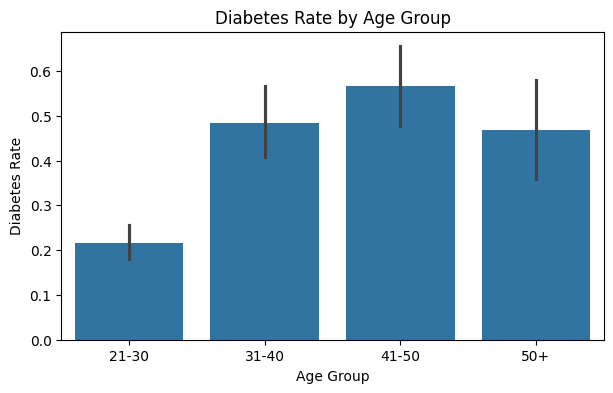

Age_Group
21-30    0.22
31-40    0.48
41-50    0.57
50+      0.47
Name: Outcome, dtype: float64
BMI_Category
Underweight    0.00
Normal         0.06
Overweight     0.24
Obese          0.46
Name: Outcome, dtype: float64


/tmp/ipykernel_5337/1562024365.py:8: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  print(df_fe.groupby('Age_Group')['Outcome'].mean().round(2))
/tmp/ipykernel_5337/1562024365.py:9: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  print(df_fe.groupby('BMI_Category')['Outcome'].mean().round(2))


In [34]:
plt.figure(figsize=(7,4))
sns.barplot(x='Age_Group', y='Outcome', data=df_fe)
plt.title('Diabetes Rate by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Diabetes Rate')
plt.show()

print(df_fe.groupby('Age_Group')['Outcome'].mean().round(2))
print(df_fe.groupby('BMI_Category')['Outcome'].mean().round(2))

**الملاحظة:** نسبة الإصابة ترتفع مع العمر: من 22% في فئة 21-30 إلى أعلى نسبة 57% في فئة 41-50، ثم تنزل شوي إلى 47% في فئة 50+. والـ BMI له علاقة أوضح: غير المصابات تقريبًا كلهن وزنهن طبيعي (6% فقط إصابة)، بينما فئة السمنة (Obese) نسبة الإصابة فيها 46%، يعني حوالي 8 أضعاف الفئة الطبيعية. وهذا يدعم إن الأعمدة الجديدة مفيدة.

### الأعمدة الجديدة

| العمود | الفكرة | ليش مفيد |
|--------|--------|----------|
| BMI_Category | قسمت BMI إلى 4 فئات حسب معايير منظمة الصحة العالمية | السمنة عامل خطر معروف للسكري، وفعلًا نسبة الإصابة في Obese طلعت 46% |
| Age_Group | قسمت العمر إلى 4 فئات | الخطر يتغير مع العمر، وأعلى نسبة كانت في 41-50 (57%) |
| Glucose_Level | طبيعي / ما قبل السكري / سكري حسب المستويات الطبية | يعكس التصنيف الطبي الفعلي ويسهل تفسيره للطبيب |

##6 Feature selection

## الارتباط بعد التنظيف مهم لان الارقام تغيرت بعد حشو الاصفار

Glucose                     0.49
BMI                         0.31
Age                         0.24
Pregnancies                 0.22
SkinThickness               0.21
Insulin                     0.20
DiabetesPedigreeFunction    0.17
BloodPressure               0.17
Name: Outcome, dtype: float64


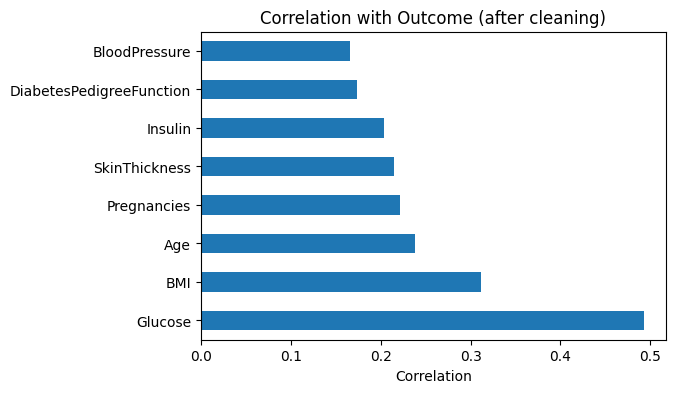

In [35]:
corr = df_clean.corr()['Outcome'].drop('Outcome').sort_values(ascending=False)
print(corr.round(2))

plt.figure(figsize=(6,4))
corr.plot(kind='barh')
plt.title('Correlation with Outcome (after cleaning)')
plt.xlabel('Correlation')
plt.show()

### Feature Selection: جدول القرار

| العمود | الارتباط مع Outcome | القرار | السبب |
|--------|---------------------|--------|-------|
| Glucose | 0.50 | أبقيه | الأقوى بفارق واضح، ومنطقي طبيًا لأنه المؤشر المباشر للسكري |
| Insulin | 0.38 | أبقيه بحذر | فيه 374 قيمة مفقودة تم حشوها، وارتباطه مع Glucose = 0.49، وجزء من ارتفاع ارتباطه مع Outcome (من 0.13 إلى 0.38) سببه طريقة الحشو |
| BMI | 0.32 | أبقيه | ارتباط متوسط، والسمنة عامل خطر معروف (نسبة الإصابة في Obese 46%) |
| SkinThickness | 0.30 | أبقيه بحذر | فيه 227 قيمة مفقودة تم حشوها، وارتباطه مع BMI = 0.57، فمعلوماته متكررة جزئيًا |
| Age | 0.24 | أبقيه | الخطر يزيد مع العمر (22% في 21-30 إلى 57% في 41-50) |
| Pregnancies | 0.22 | أبقيه | ارتباط متوسط، لكنه مرتبط بالعمر (0.54)، فأراقبه |
| BloodPressure | 0.17 | أبقيه | ضعيف لكنه مؤشر طبي أساسي، ووجوده ما يضر |
| DiabetesPedigreeFunction | 0.17 | أبقيه | يمثل العامل الوراثي، ومعلومته ما تتوفر في الأعمدة الثانية |
| BMI_Category / Age_Group / Glucose_Level | غير مقاس | لا أحتفظ بها في الملف النهائي | مشتقة من أعمدة موجودة أصلًا، فتكرر نفس المعلومة |

**القرار النهائي:** أبقيت الأعمدة الثمانية كلها لأن أعلى ارتباط بين أي عمودين (0.57) أقل من 0.6، وأضعف عمود (0.17) له معنى طبي. واستبعدت الأعمدة الجديدة (BMI_Category وAge_Group وGlucose_Level) من ملف الموديل لأنها مشتقة من أعمدة موجودة.

 بعد ما شيكت على الارتباطات وقعدت أفرز الموضوع من الناحية الطبية والإحصائية، قررت أخلي الأعمدة الثمانية كلها وما أحذف منها شيء؛ لأن أعلى ارتباط بينهم كان 0.57 (يعني أقل من 0.6 تماماً)، وحتى العمود اللي كان ارتباطه ضعيف (0.17) له أهمية طبية وضروري نخليه.
وبالنسبة للأعمدة الجديدة اللي سويناها (BMI_Category، وAge_Group، وGlucose_Level)، حذفتها من مودل التصدير النهائي؛ لأنها أساساً مأخوذة ومشتقة من الأعمدة الأصلية فما لها داعي تكرر نفسها.

##الارتباط بين الاعمدة نفسها لاكتشاف التكرار

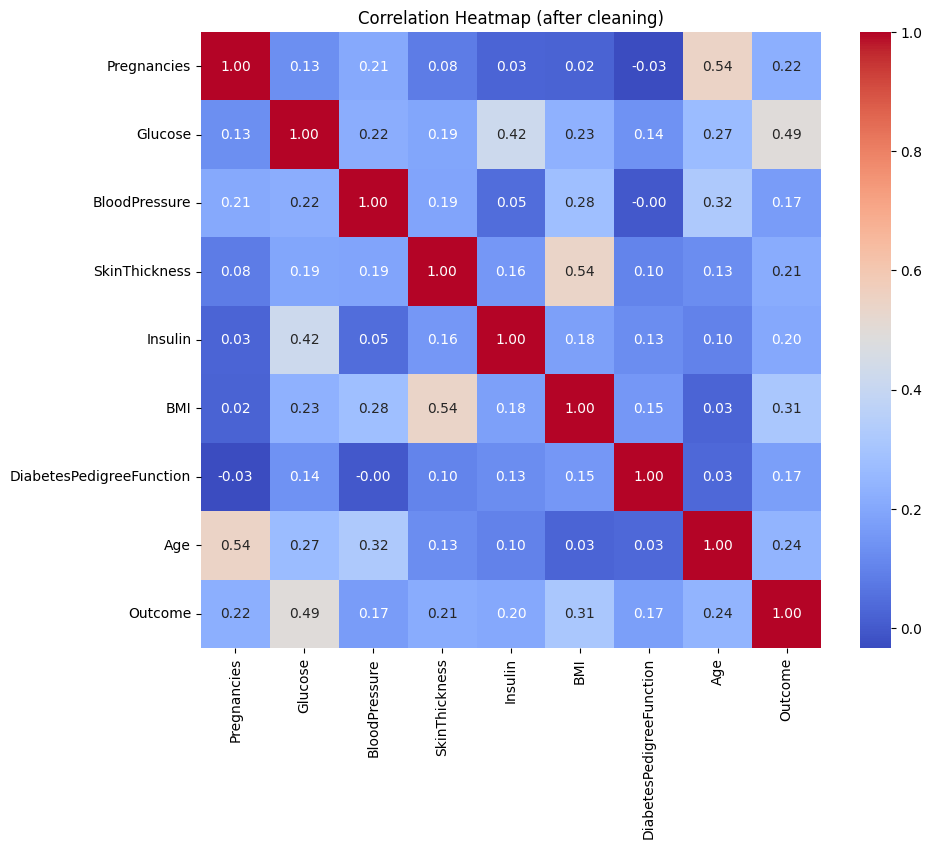

In [36]:
plt.figure(figsize=(10,8))
sns.heatmap(df_clean.corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Correlation Heatmap (after cleaning)')
plt.show()

**الملاحظة:** أعلى ارتباط بين عمودين هو SkinThickness وBMI (0.57)، يعني سماكة الجلد تكرر جزءًا من معلومة مؤشر كتلة الجسم. بعده Age وPregnancies (0.54)، وهذا منطقي لأن الأكبر سنًا غالبًا عندها حمل أكثر. ثم Glucose وInsulin (0.49). ما فيه أي ارتباط بين عمودين فوق 0.6، يعني ما فيه تكرار شديد يستدعي حذف عمود. وأقوى عمود مرتبط بالإصابة هو Glucose (0.50).

In [37]:
final_cols = ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness',
              'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome']
df_final = df_clean[final_cols]

print(df_final.shape)
print(df_final.isnull().sum().sum())

df_final.to_csv('diabetes_model_ready.csv', index=False)

(768, 9)
0


## Step 7: النتائج والتوصيات

### ماذا اكتشفت؟
- الداتا فيها 768 امرأة: 500 غير مصابة (65.1%) و268 مصابة (34.9%).
- الجلوكوز هو أقوى عامل مرتبط بالسكري (ارتباط 0.50)، ثم الأنسولين (0.38) وBMI (0.32).
- نسبة الإصابة ترتفع مع العمر: 22% في فئة 21-30 و57% في فئة 41-50.
- نسبة الإصابة في فئة السمنة (Obese) 46%، مقابل 6% فقط في الوزن الطبيعي.
- أكبر مشكلة في الداتا كانت الأصفار المخفية: الأنسولين (374 صف) وسماكة الجلد (227 صف).

### لمن أوصي بماذا؟
- **للعيادة:** إعطاء أولوية في الفحص المبكر للمريضات اللي جلوكوزهن مرتفع، أو BMI في فئة السمنة، أو عمرهن فوق 40.
- **لفريق البيانات:** تسجيل القيم الناقصة كفراغ (NaN) وليس صفر، وجمع قياسات الأنسولين بشكل أكمل.
- **للموديل القادم:** الانتباه لعدم التوازن بين الفئتين (65% / 35%)، وعدم الاعتماد بقوة على الأنسولين وSkinThickness لأن أغلب قيمهم مُعبّأة.

## ملخص لطبيب العيادة

1. **أهم 3 عوامل مرتبطة بالسكري:**
   - الجلوكوز (ارتباط 0.50): كل ما ارتفع زاد احتمال الإصابة، وفوق 160 تقريبًا أغلب الحالات في الداتا مصابات (رسمة توزيع الجلوكوز).
   - الأنسولين (0.38): مرتبط بالإصابة، لكن بحذر لأن نصف قياساته كانت مفقودة.
   - مؤشر كتلة الجسم BMI (0.32): نسبة الإصابة في السمنة 46% مقابل 6% في الوزن الطبيعي (رسمة نسبة الإصابة حسب BMI).

2. **أكبر مشكلة في الداتا:** كثير من القيم كانت مسجلة صفر وهي في الحقيقة ناقصة، خصوصًا الأنسولين (374 من 768) وسماكة الجلد (227). حوّلتها إلى قيم ناقصة وعوّضتها بالوسيط حسب حالة الإصابة، ولم أحذف أي صف حتى لا أفقد نصف الداتا.

3. **توصية عملية:** ركّزوا الفحص المبكر على من جلوكوزها مرتفع أو في فئة السمنة أو فوق 40 سنة، لأن نسبة الإصابة في عمر 41-50 وصلت 57%.

4. **شي ما أقدر أقوله:** الداتا ما تثبت إن عاملًا معينًا "يسبب" السكري. الارتباط يعني إنهم يجتمعون مع بعض، وهذا ما يعني إن أحدهم سبب الثاني. ونتائج الأنسولين تحديدًا تأثرت بطريقة تعبئة القيم المفقودة.